> **Archived N0 run (2026-11-09).** Notebook 07 (open- vs closed-loop failure baseline) with the superseded sensor model N0 (σ = 0.5% of each channel's window maximum). Kept for the record and for the N0-vs-N3 comparison in the paper; the production version is the notebook without the `_N0` suffix. Re-running this copy requires `data/observations_N0.npz` to be copied back to `data/observations.npz`.

# 07 — Failure baseline: open-loop vs. closed-loop SBI (Claim 1)

The **headline experiment** for the paper's first claim:

> SBI trained on a **closed-loop** simulator diagnoses faults that the PI controller masks,
> while an SBI trained on an **open-loop** simulator misreads the same observations.

## Experiment design (2026-11-08 run)

| SBI model | Training data | Applied to |
|---|---|---|
| **Closed-loop SBI** (production posterior, nb31) | 160k windows from the 2-D prior [α, β], closed-loop simulator, P1b warm start; 5-seed ensemble | Sc2 (closed-loop data) and Sc6 (open-loop data), both α = 1, β = 0.85 |
| **Open-loop SBI** | 160k windows from the same prior, open-loop simulator (Qc fixed at 80 L/min), 300-min burn-in; single seed | the same observations |

Both use the same 29-D summaries and NSF recipe; the only difference is whether the training
simulator contains the PI controller. Caveat: the closed-loop posterior is a 5-seed ensemble,
the open-loop one a single seed (seed 7).

## What each model should do
- On **Sc2** the controller holds T at its setpoint and absorbs the fouling by raising Qc.
  A model trained without a controller reads fouling through a temperature rise, which is
  absent, and has never seen Qc vary: it should miss or misattribute the fault.
- On **Sc6** (open loop) the roles reverse: the closed-loop model is the misspecified one.

> **2026-11-08 revision.** Run after notebook 02 (regenerated P1b data) and nb31 (production
> closed-loop posterior). Sc2/Sc6 have β = 0.85. Execute from `notebooks/system_I`.
> The open-loop posterior is cached after the first run (`RUN_OL_TRAINING = False`; set True to
> retrain, ~18 min). Section 3b measures how much of each posterior lies outside the prior and
> recomputes the metrics on in-prior samples; section 7 interprets the results.

## 1. Setup

In [7]:
import os
os.environ["CSTR_SENSOR_MODEL"] = "N0"   # archival N0 run (default model is N3 since 2026-11-09)
from __future__ import annotations
import json, pickle, time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import torch

from cstr_sbi.inference import sample_posterior, train_sbi_posterior
from cstr_sbi.metrics import classify_fault, compute_wasserstein, compute_crps, summarise_posterior
from cstr_sbi.physics import (
    K0_NOMINAL, UA_NOMINAL, NOMINAL_CTRL, NOMINAL_INLET_CL,
    NOMINAL_Y0_CL, CI_NOMINAL,
)
from cstr_sbi.priors import box_uniform_2d
from cstr_sbi.scenarios import SCENARIO_CONFIGS
from cstr_sbi.simulator import (
    simulate_em_window_open_loop, apply_sensor_layer,
    DEFAULT_SENSOR_NOISE_PCT, DEFAULT_PROCESS_SIGMA,
)
from cstr_sbi.summaries import compute_summary_statistics, compute_summary_statistics_batch

jax.config.update("jax_enable_x64", False)

import sys
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", \
    f"execute this notebook from notebooks/system_I (cwd is {NB_DIR})"
ROOT    = NB_DIR.parent.parent
for _p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(_p))
DATA    = ROOT / "data" / "observations.npz"
RESULTS = ROOT / "results"
FIGS    = ROOT / "figures"

# Closed-loop production posterior (2026-11-08: fixed controller law, P1b warm start,
# budget/ensemble chosen by nb31). Replaces the old sbi_posterior_final.pkl.
from nb31_budget_convergence import load_production_posterior
posterior_cl, PROD = load_production_posterior()
print(f"Closed-loop production posterior loaded: protocol {PROD['protocol']}, "
      f"budget {PROD['production_budget']}, {'ensemble' if PROD['use_ensemble'] else 'single seed'}")
_d = np.load(DATA, allow_pickle=False)
assert "protocol" in _d.files and str(_d["protocol"]) == PROD["protocol"], \
    "data/observations.npz is not the regenerated P1b dataset: re-run notebook 02 first"

# Load observations
d_obs = np.load(DATA, allow_pickle=False)
x_all     = jnp.asarray(d_obs["x"])    # (400, 120, 4)
t         = jnp.asarray(d_obs["t"])
sid       = d_obs["scenario_id"]
theta_all = d_obs["theta"]

S_all = np.asarray(compute_summary_statistics_batch(x_all, t))
print(f"Summaries: {S_all.shape}  NaN={np.isnan(S_all).sum()}")


Closed-loop production posterior loaded: protocol P1b, budget 160000, ensemble
Summaries: (400, 29)  NaN=0


## 2. Train open-loop SBI (OL posterior)

Train a second NSF posterior using the **open-loop simulator** (Qc fixed at Qc0=80 L/min).
Same prior, same density estimator, same n_simulations — **only the simulator differs**.
This is the "naive" model that an engineer might deploy without knowing whether
the plant operates in open- or closed-loop mode.


In [8]:
# 2026-11-08: open-loop posterior retrained on the SAME open-loop simulator that generates
# Sc0/Sc6 in notebook 02 (ws_eval.simulate_open_loop: 300-min noisy burn-in at the sampled
# theta before the window), with the production recipe and budget of the closed-loop posterior
# (nb31), so the open- vs closed-loop comparison differs only by the simulator's control mode.
# Previous version: per-draw noise-free open-loop steady state, no burn-in (open-loop P1).
import ws_eval as we
RUN_OL_TRAINING = False   # trained 2026-11-08 (160k, seed 7); True retrains (~18 min)
OL_PATH = RESULTS / "sbi_posterior_open_p1b.pkl"
N_OL = int(PROD["production_budget"])

if RUN_OL_TRAINING or not OL_PATH.exists():
    t0 = time.perf_counter()
    theta_ol = we.prior_draws(N_OL, seed=7007)
    x_ol = we.simulate_open_loop(theta_ol, seed=7_007_000)
    print(f"simulated {x_ol.shape} open-loop training summaries in {time.perf_counter() - t0:.0f}s")
    posterior_ol, meta_ol = we.train_npe(theta_ol, x_ol, seed=7)
    with open(OL_PATH, "wb") as f:
        pickle.dump({"posterior": posterior_ol, "metadata": {**meta_ol, "simulator": "ws_eval.simulate_open_loop",
                                                              "burn_min": 300.0}}, f)
    print(f"OL training done: {meta_ol}")
else:
    with open(OL_PATH, "rb") as f:
        posterior_ol = pickle.load(f)["posterior"]
    print("Loaded cached OL posterior")

Loaded cached OL posterior


## 3. Apply both posteriors to Sc2 and Sc6 observations

- **Sc2** (closed-loop, β=0.70): the fault the model was trained to detect; CL SBI should work, OL SBI should struggle.
- **Sc6** (open-loop, β=0.70): observations generated with fixed Qc; OL SBI should be better specified, CL SBI is misspecified.


In [9]:
N_REP = 50  # use all 50 replicates per scenario
N_SAMP = 2_000

results = {}
for sc_id, label in [(2, "Sc2_CL_fouling"), (6, "Sc6_OL_fouling")]:
    mask = np.where(sid == sc_id)[0][:N_REP]
    sc_summaries = S_all[mask]          # (N_REP, 29)
    sc_theta     = theta_all[mask]      # (N_REP, 4)
    beta_true    = float(sc_theta[0, 3])
    alpha_true   = float(sc_theta[0, 2])

    samps_cl, samps_ol = [], []
    for s in sc_summaries:
        samps_cl.append(sample_posterior(posterior_cl, s, n_samples=N_SAMP))
        samps_ol.append(sample_posterior(posterior_ol, s, n_samples=N_SAMP))

    samps_cl = np.stack(samps_cl)   # (N_REP, N_SAMP, 2)
    samps_ol = np.stack(samps_ol)

    results[sc_id] = dict(
        label=label, alpha_true=alpha_true, beta_true=beta_true,
        samps_cl=samps_cl, samps_ol=samps_ol,
    )
    print(f"Sc{sc_id} (β_true={beta_true}):")
    print(f"  CL SBI:  β_mean={samps_cl[:,:,1].mean():.3f}  "
          f"β_cov90={np.mean([np.percentile(samps_cl[i,:,1],5)<=beta_true<=np.percentile(samps_cl[i,:,1],95) for i in range(N_REP)]):.2f}  "
          f"fault_acc={np.mean([classify_fault(samps_cl[i])['class']=='fouling_dominant' for i in range(N_REP)]):.2f}")
    print(f"  OL SBI:  β_mean={samps_ol[:,:,1].mean():.3f}  "
          f"β_cov90={np.mean([np.percentile(samps_ol[i,:,1],5)<=beta_true<=np.percentile(samps_ol[i,:,1],95) for i in range(N_REP)]):.2f}  "
          f"fault_acc={np.mean([classify_fault(samps_ol[i])['class']=='fouling_dominant' for i in range(N_REP)]):.2f}")


/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/src/cstr_sbi/inference.py:694: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples = posterior.sample(


Sc2 (β_true=0.8500000238418579):
  CL SBI:  β_mean=0.861  β_cov90=0.94  fault_acc=0.96
  OL SBI:  β_mean=1.008  β_cov90=0.00  fault_acc=0.28
Sc6 (β_true=0.8500000238418579):
  CL SBI:  β_mean=0.915  β_cov90=0.50  fault_acc=0.38
  OL SBI:  β_mean=0.856  β_cov90=0.94  fault_acc=0.88


## 3b. How much of each posterior lies outside the prior? (added 2026-11-08)
Both models are applied to data from the *other* simulator in one of the two scenarios, i.e. to
summaries outside their training distribution (for the open-loop model, any Qc variation at all:
Qc is constant in its training data). Out-of-support samples are the signature of that
extrapolation.

In [10]:
# Section 3b -- sample_posterior draws WITHOUT restricting to the prior box (reject_outside_prior=False);
# a warning above reported that for at least one (posterior, scenario) pair all samples fall outside it.
# Measure that, and recompute the beta metrics on the in-prior samples only.
from cstr_sbi.priors import ALPHA_LOW, ALPHA_HIGH, BETA_LOW, BETA_HIGH
LO, HI = np.array([ALPHA_LOW, BETA_LOW]), np.array([ALPHA_HIGH, BETA_HIGH])
rows_leak = []
for sc_id in [2, 6]:
    r = results[sc_id]
    for samps, model in [(r["samps_cl"], "CL-SBI"), (r["samps_ol"], "OL-SBI")]:
        inside = np.all((samps >= LO) & (samps <= HI), axis=2)          # (N_REP, N_SAMP)
        cov, acc, bmean = [], [], []
        for i in range(samps.shape[0]):
            v = samps[i][inside[i]]
            if len(v) < 50:
                continue
            lo5, hi95 = np.percentile(v[:, 1], [5, 95])
            cov.append(lo5 <= r["beta_true"] <= hi95)
            acc.append(classify_fault(v)["class"] == "fouling_dominant")
            bmean.append(v[:, 1].mean())
        rows_leak.append(dict(
            scenario=f"Sc{sc_id}", model=model, frac_outside_prior=float(1 - inside.mean()),
            alpha_mean_raw=float(samps[:, :, 0].mean()), beta_mean_raw=float(samps[:, :, 1].mean()),
            n_windows_with_50_inside=len(cov),
            beta_mean_inprior=float(np.mean(bmean)) if bmean else np.nan,
            beta_cov90_inprior=float(np.mean(cov)) if cov else np.nan,
            fault_acc_inprior=float(np.mean(acc)) if acc else np.nan,
            class_counts_raw=pd.Series([classify_fault(samps[i])["class"] for i in range(samps.shape[0])]).value_counts().to_dict()))
import pandas as pd
df_leak = pd.DataFrame(rows_leak)
display(df_leak)
df_leak.to_csv(RESULTS / "07_cl_vs_ol_prior_leakage.csv", index=False)
print("A model whose samples lie largely outside the prior is extrapolating beyond its training data:"
      " its point estimates are not interpretable as inference, only its failure is.")

,scenario,model,frac_outside_prior,alpha_mean_raw,beta_mean_raw,n_windows_with_50_inside,beta_mean_inprior,beta_cov90_inprior,fault_acc_inprior,class_counts_raw
0,Sc2,CL-SBI,0.00001,1.000061,0.860798,50,0.860798,0.94,0.960000,"{'fouling_dominant': 48, 'healthy': 2}"
1,Sc2,OL-SBI,0.94000,1.374761,1.007648,3,0.720200,0.00,0.333333,"{'healthy': 32, 'fouling_dominant': 14, 'combi..."
2,Sc6,CL-SBI,0.00002,1.002535,0.914871,50,0.914882,0.50,0.380000,"{'healthy': 31, 'fouling_dominant': 19}"
3,Sc6,OL-SBI,0.00017,1.000346,0.856313,50,0.856312,0.94,0.880000,"{'fouling_dominant': 44, 'healthy': 6}"


A model whose samples lie largely outside the prior is extrapolating beyond its training data: its point estimates are not interpretable as inference, only its failure is.


## 4. Head-to-head comparison: β posterior distributions

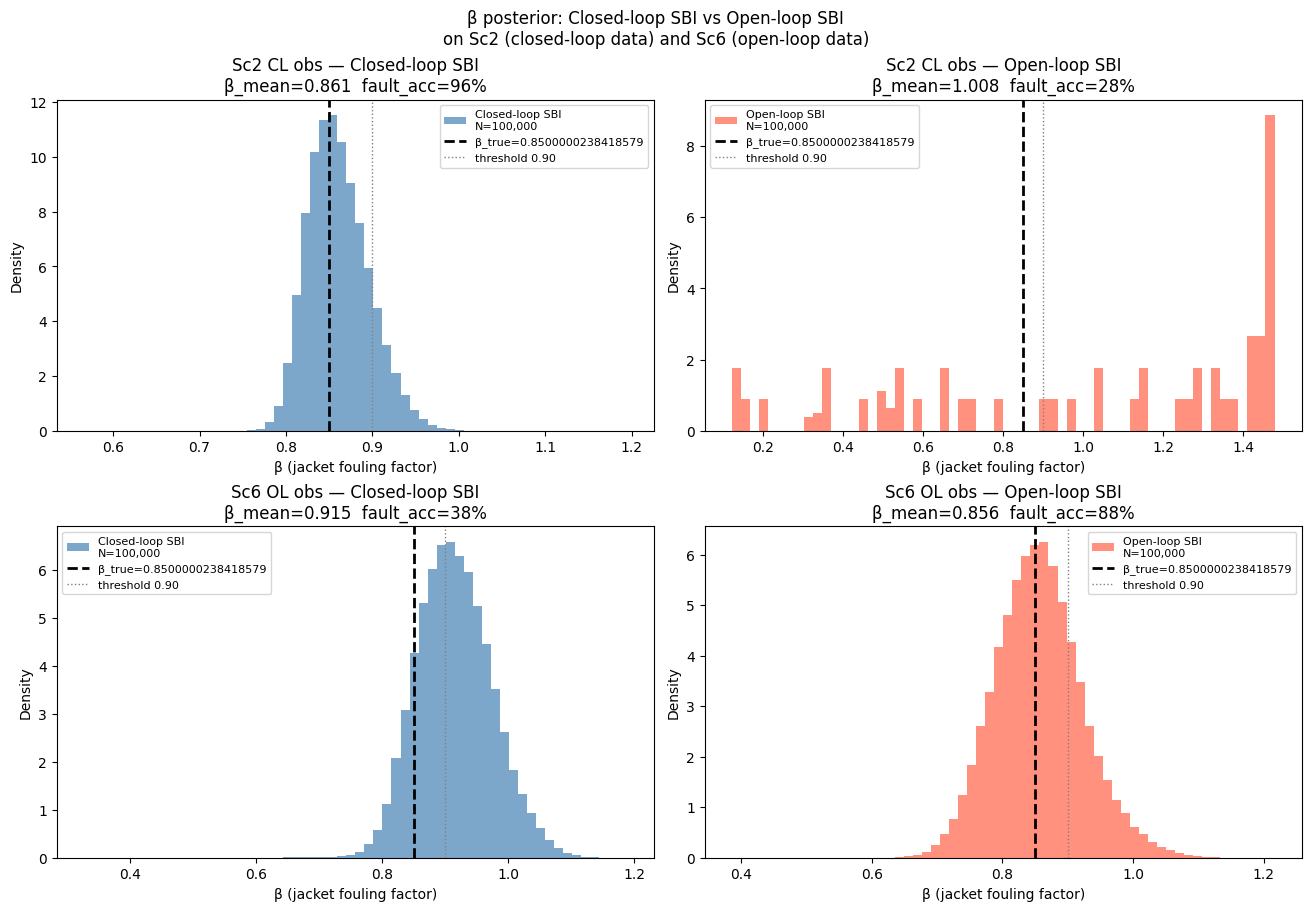

Saved 07_cl_vs_ol_beta_posteriors.png


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)

for row, sc_id in enumerate([2, 6]):
    r = results[sc_id]
    beta_true = r['beta_true']

    for col, (samps, label, color) in enumerate([
        (r['samps_cl'], "Closed-loop SBI", "steelblue"),
        (r['samps_ol'], "Open-loop SBI",   "tomato"),
    ]):
        ax = axes[row, col]
        # Pool all replicates for a pooled marginal
        pooled_beta = samps[:, :, 1].ravel()
        ax.hist(pooled_beta, bins=60, density=True, color=color, alpha=0.7,
                label=f"{label}\nN={len(pooled_beta):,}")
        ax.axvline(beta_true, color="k", lw=2, ls="--", label=f"β_true={beta_true}")
        # 0.85 -> 0.90 (2026-08-17, HANDOFF.md TOP PRIORITY / Item 8): tracks
        # classify_fault's recalibrated threshold.
        ax.axvline(0.90, color="gray", lw=1, ls=":", label="threshold 0.90")
        ax.set_xlabel("β (jacket fouling factor)")
        ax.set_ylabel("Density")
        fault_acc = np.mean([classify_fault(samps[i])['class']=='fouling_dominant'
                             for i in range(samps.shape[0])])
        beta_mean = samps[:,:,1].mean()
        ax.set_title(f"{'Sc2 CL obs' if sc_id==2 else 'Sc6 OL obs'} — {label}\n"
                     f"β_mean={beta_mean:.3f}  fault_acc={fault_acc:.0%}")
        ax.legend(fontsize=8)

fig.suptitle("β posterior: Closed-loop SBI vs Open-loop SBI\n"
             "on Sc2 (closed-loop data) and Sc6 (open-loop data)", fontsize=12)
fig.savefig(FIGS / "07_cl_vs_ol_beta_posteriors.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved 07_cl_vs_ol_beta_posteriors.png")

## 5. W1 and CRPS: quantitative comparison

In [12]:
rows_metrics = []
for sc_id in [2, 6]:
    r = results[sc_id]
    beta_true = r['beta_true']
    for samps, model in [(r['samps_cl'], "CL-SBI"), (r['samps_ol'], "OL-SBI")]:
        w1  = np.mean([compute_wasserstein(samps[i,:,1], [beta_true]*N_SAMP) for i in range(N_REP)])
        crps = np.mean([compute_crps(samps[i,:,1], beta_true) for i in range(N_REP)])
        fault_acc = np.mean([classify_fault(samps[i])['class']=='fouling_dominant' for i in range(N_REP)])
        rows_metrics.append(dict(scenario=f"Sc{sc_id}", model=model,
                                 beta_true=beta_true,
                                 beta_mean=float(samps[:,:,1].mean()),
                                 W1_beta=w1, CRPS_beta=crps, fault_acc=fault_acc))

import pandas as pd
df_m = pd.DataFrame(rows_metrics)
print(df_m.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Save
df_m.to_csv(RESULTS / "07_cl_vs_ol_metrics.csv", index=False)
print("\nSaved 07_cl_vs_ol_metrics.csv")


scenario  model  beta_true  beta_mean  W1_beta  CRPS_beta  fault_acc
     Sc2 CL-SBI     0.8500     0.8608   0.0285     0.0140     0.9600
     Sc2 OL-SBI     0.8500     1.0076   0.4373     0.4373     0.2800
     Sc6 CL-SBI     0.8500     0.9149   0.0717     0.0491     0.3800
     Sc6 OL-SBI     0.8500     0.8563   0.0526     0.0247     0.8800

Saved 07_cl_vs_ol_metrics.csv


## 6. α-β joint posteriors (Sc2 CL and Sc6 OL)

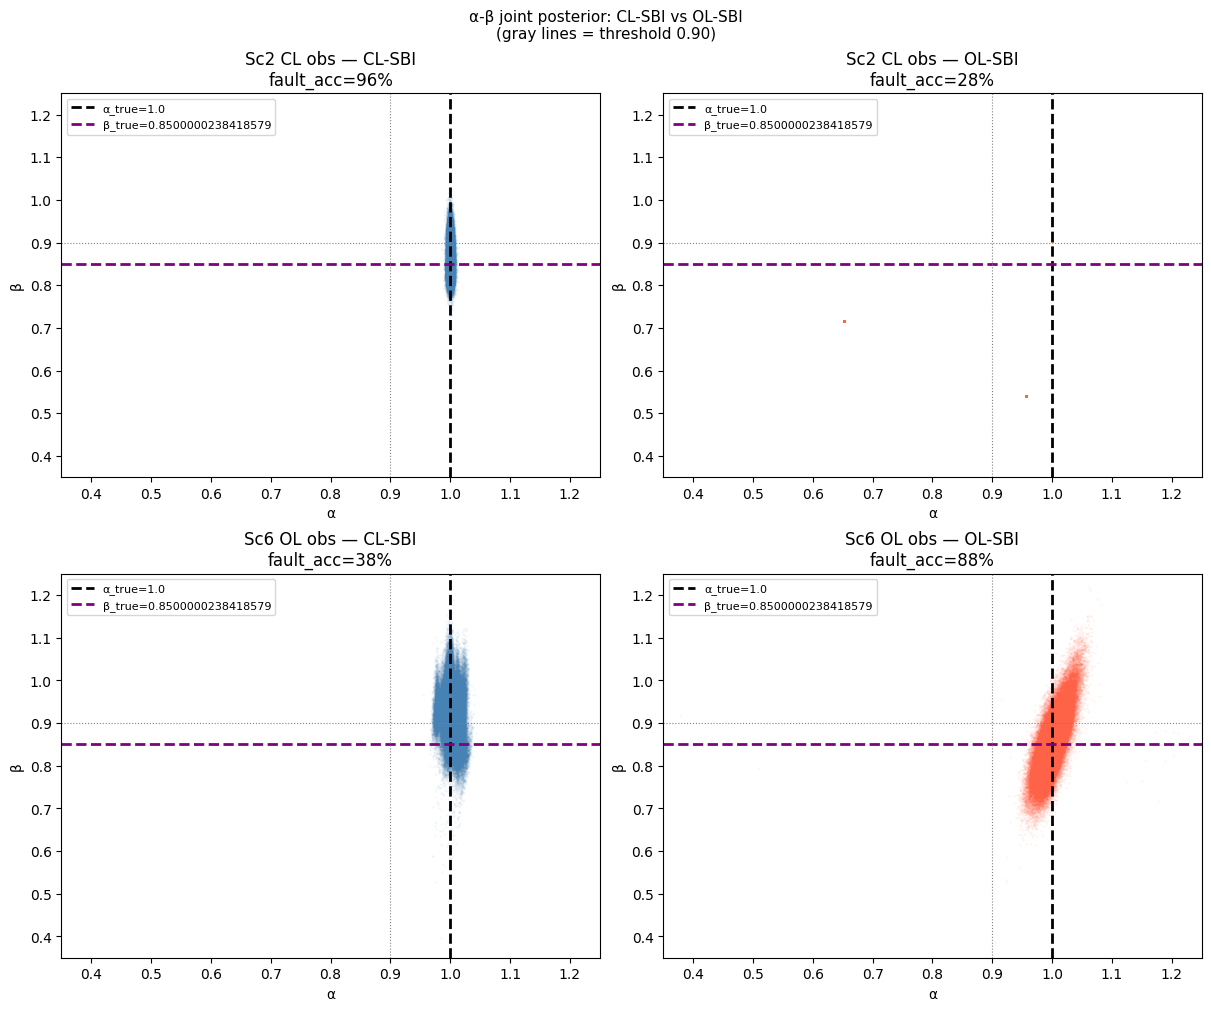

Saved 07_cl_vs_ol_joint.png


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)

for row, sc_id in enumerate([2, 6]):
    r = results[sc_id]
    for col, (samps, label, color) in enumerate([
        (r['samps_cl'], "CL-SBI", "steelblue"),
        (r['samps_ol'], "OL-SBI", "tomato"),
    ]):
        ax = axes[row, col]
        pooled = samps.reshape(-1, 2)
        ax.scatter(pooled[:,0], pooled[:,1], s=0.5, alpha=0.05, color=color)
        ax.axvline(r['alpha_true'], color="k", lw=2, ls="--", label=f"α_true={r['alpha_true']}")
        ax.axhline(r['beta_true'],  color="purple", lw=2, ls="--", label=f"β_true={r['beta_true']}")
        # 0.85 -> 0.90 (2026-08-17, HANDOFF.md TOP PRIORITY / Item 8): tracks
        # classify_fault's recalibrated threshold.
        ax.axvline(0.90, color="gray", lw=0.8, ls=":")
        ax.axhline(0.90, color="gray", lw=0.8, ls=":")
        ax.set_xlabel("α"); ax.set_ylabel("β")
        ax.set_xlim(0.35, 1.25); ax.set_ylim(0.35, 1.25)   # the whole prior box [0.4, 1.2]^2
        fault_acc = np.mean([classify_fault(samps[i])['class']=='fouling_dominant' for i in range(N_REP)])
        ax.set_title(f"{'Sc2 CL obs' if sc_id==2 else 'Sc6 OL obs'} — {label}\nfault_acc={fault_acc:.0%}")
        ax.legend(fontsize=8)

fig.suptitle("α-β joint posterior: CL-SBI vs OL-SBI\n(gray lines = threshold 0.90)", fontsize=11)
fig.savefig(FIGS / "07_cl_vs_ol_joint.png", dpi=120, bbox_inches="tight")
plt.show()
print("Saved 07_cl_vs_ol_joint.png")

## 7. Results commentary and Claim 1 assessment (2026-11-08 run)

Supersedes the August 2026 commentary, which described a run with the old (weak-integral)
controller, the noise-free warm start and Sc2/Sc6 at β = 0.70. Numbers from sections 3, 3b and 5.

| | CL-SBI on Sc2 (CL data) | OL-SBI on Sc2 (CL data) | CL-SBI on Sc6 (OL data) | OL-SBI on Sc6 (OL data) |
|---|---|---|---|---|
| β posterior mean (true 0.85) | **0.861** | not interpretable (94% of samples outside the prior; raw α̂ = 1.37) | 0.915 | **0.856** |
| fraction of samples outside the prior | 0.001% | **94%** | 0.002% | 0.02% |
| β 90% coverage | **0.94** | 0.00 | 0.54 | **0.94** |
| fault-class accuracy | **0.96** | 0.28 | 0.38 | **0.88** |
| W1(β) | **0.029** | 0.437 | 0.071 | **0.053** |
| CRPS(β) | **0.014** | 0.437 | 0.049 | **0.025** |

### Claim 1 — supported, with a clearer mechanism than before

**Sc2 (closed-loop observations).** The closed-loop posterior recovers the fault: β̂ = 0.861,
coverage 0.94, 96% of windows classified as fouling. The open-loop posterior **cannot explain the
closed-loop data at all**: 94% of its posterior mass lies outside the prior (raw α̂ = 1.37,
beyond the prior's upper bound of 1.2; only 3 of 50 windows have even 50 in-prior samples), it
never covers the truth, and it classifies 32 of 50 windows as healthy and only 14 (28%) as
fouling. The mechanism is masking: the PI loop holds T at its setpoint and absorbs the fault by
raising Qc. A model trained without a controller identifies fouling through a temperature rise,
which the controller has removed, and has never seen Qc vary (it is fixed in its training data),
so the channel that carries the fault lies outside anything it was trained on and the network
extrapolates, here into an impossibly active catalyst. Its point estimate is therefore not a
physical inference; its failure is the result: a missed detection in most windows.
*(The August run reported the opposite failure, β̂ ≈ 0.15. That came from the 150×-too-weak
integral action, which let T drift within the window; it should not be cited.)*

**Sc6 (open-loop observations).** The mismatch reverses, and here it is a genuine,
in-prior bias rather than extrapolation (leakage 0.002%): the open-loop posterior is right
(β̂ = 0.856, coverage 0.94, accuracy 0.88) and the closed-loop one is biased towards health
(β̂ = 0.915, coverage 0.54, accuracy 0.38). The reversal is weaker than on Sc2 (W1 1.4×, CRPS
2× rather than 15×), because β = 0.85 is a mild fault and the open-loop signature it leaves
(a rise in T at fixed Qc) is partly readable by a closed-loop model too. The August numbers
(accuracy 0.04 vs 1.00) were for β = 0.70.

**Accuracy below 100% on the matched pairs (0.96, 0.88)** is expected: β = 0.85 is only 0.05
below the 0.90 threshold (the incipient-fault case by design).

**Net picture.** Each posterior is right on data from its own simulator and wrong on the
other; for closed-loop plant data the specific failure of the open-loop model is a **missed
detection**, the operationally dangerous one. That is the quantitative evidence for Claim 1.

**Prior leakage as a misspecification alarm.** The leakage fraction separates the cases
cleanly: ≤ 0.02% whenever a posterior meets data from its own simulator, 94% for the
open-loop model on closed-loop data. It costs nothing to compute and could be reported as a
deployment-time check (cf. the misspecification tests of Schmitt et al. and the MMD check
planned in nb29 E5). Caveat: the closed-loop model on open-loop data (Sc6) does *not* leak, so
leakage detects gross misspecification, not every mismatch.

### Remaining check before the numbers go into the paper
**Ensemble vs single seed.** The closed-loop model is a 5-seed ensemble, the open-loop one a
   single seed. The gap on Sc2 (15× in W1) is far larger than seed-to-seed variation, but a
   5-seed open-loop ensemble would make the comparison strictly like-for-like.

### The constant-feature warning in section 2
`Data has constant values in dimension(s) [25, 26]` refers to `Qc_sat_low_frac` and
`Qc_sat_high_frac`: with Qc fixed at 80 L/min the valve never saturates in open-loop training
data. Expected and harmless (sbi maps them to zero after z-scoring). The other Qc features
vary only by sensor noise in the open-loop training data, which is why any real Qc variation
is far outside that model's training distribution. Open-loop training: 160k simulations,
36 epochs, 410 s.

### Paper framing
`main.tex` §`sec:model_mismatch_results` must be rewritten with these numbers: Sc2 closed-loop
model β̂ 0.861, coverage 0.94, accuracy 0.96; open-loop model 94% of posterior mass outside the
prior, coverage 0, accuracy 0.28 (missed detection; W1 0.437 vs 0.029, computed on unrestricted
samples and only indicative); Sc6
reversal accuracy 0.88 vs 0.38. The old "degradation of 288%" and "1.0 to 0.06" figures are
from the old controller law and β = 0.70. Key figure: `07_cl_vs_ol_beta_posteriors.png`;
table: `07_cl_vs_ol_metrics.csv`, with `07_cl_vs_ol_prior_leakage.csv` for the leakage caveat.